# Week 2 Day 2 - Orchestration
Our first Agentic Framework project!!

## Part 1: Email Setup
## Part 2: Orchestrating by code
## Part 3: Orchestrating by LLMs
    3a: via Tools
    3b: via Handoffs
# Part 1: Email Setup

# Setting up to send emails from your SMTP server
## STEP 1: Determining your SMTP Server
Either google or ask ChatGPT / Claude for the SMTP server for your email. Here are some common ones. Some email providers might not have SMTP servers enabled (eg Microsoft 365 for work/school).

Google: smtp.gmail.com
Outlook.com / Hotmail / Live: smtp-mail.outlook.com
Microsoft 365: smtp.office365.com
iCloud Mail: smtp.mail.me.com

Add to your .env file:

`EMAIL_SMTP_SERVER=xxxx`

## STEP 2: Obtain an app specific password
Google how to do this for your email provider. For gmail, you need to have 2-step verification on. Then visit this page:

https://myaccount.google.com/apppasswords

Give it any name; copy the password and add it to your .env file, removing the spaces that it adds. (It should be 16 characters, no spaces.)

`EMAIL_APP_PASSWORD=xxxx`

## STEP 3: Add in your email address:
`EMAIL_ADDRESS=xxx`

Remember to Save the .env file!

In [1]:
from dotenv import load_dotenv
import requests
from agents import Agent, Runner, trace, function_tool, ModelSettings
from agents.extensions.visualization import draw_graph
from openai.types.responses import ResponseTextDeltaEvent
import os
import asyncio
import smtplib  
from email.message import EmailMessage
load_dotenv(override=True)
MODEL_NAME = os.getenv("BEDROCK_MODEL")

In [2]:
EMAIL_ADDRESS = os.getenv("EMAIL_ADDRESS")
EMAIL_SMTP_SERVER = os.getenv("EMAIL_SMTP_SERVER")
EMAIL_APP_PASSWORD = os.getenv("EMAIL_APP_PASSWORD")

if EMAIL_ADDRESS:
    print("Email address is set")
else:
    print("Email address is not set")

if EMAIL_SMTP_SERVER:
    print("SMTP server is set")
else:
    print("SMTP server is not set")

if EMAIL_APP_PASSWORD:
    print("App password is set")
else:
    print("App password is not set")

USE_EMAIL = EMAIL_ADDRESS and EMAIL_SMTP_SERVER and EMAIL_APP_PASSWORD

if USE_EMAIL:
    print("Email is set up and we will try using it")
else:
    print("Email is not set up; we will send push notifications instead")

Email address is set
SMTP server is set
App password is set
Email is set up and we will try using it


In [3]:
# function to send email

def send_email(subject, text_body, html_body):
    msg = EmailMessage()
    msg["From"] = EMAIL_ADDRESS
    msg["To"] = EMAIL_ADDRESS
    msg["Subject"] = subject
    msg.set_content(text_body)
    msg.add_alternative(html_body, subtype="html")

    with smtplib.SMTP(EMAIL_SMTP_SERVER, 587) as server:
        server.starttls()
        server.login(EMAIL_ADDRESS, EMAIL_APP_PASSWORD)
        server.send_message(msg)

In [4]:
send_email("Testing testing 123", "Fingers crossed..", "<html><body><strong>Fingers</strong> crossed..</body></html>")

## If this didn't work, then uncomment the below so that we don't use emails

In [5]:
# USE_EMAIL = False

## Our fallback strategy - send a push

In [6]:
# settings for pushover notifications
pushover_user = os.getenv("PUSHOVER_USER")
pushover_token = os.getenv("PUSHOVER_TOKEN")
pushover_url = "https://api.pushover.net/1/messages.json"

if pushover_user:
    if pushover_user.startswith("u"):
        print("Pushover user found and looks good")
    else:
        print("Pushover user found but doesn't start with u")
else:
    print("Pushover user not found")

if pushover_token:
    if pushover_token.startswith("a"):
        print("Pushover token found and looks good")
    else:
        print("Pushover token found but doesn't start with a")
else:
    print("Pushover token not found")

Pushover user found and looks good
Pushover token found and looks good


In [7]:
# Function to send push notifications using Pushover
def push(message):
    print(f"Push: {message}")
    payload = {"user": pushover_user, "token": pushover_token, "message": message}
    requests.post(pushover_url, data=payload)

In [8]:
# function to send message either via email or push notification
def send_message(subject, text_body, html_body):
    if USE_EMAIL:
        send_email(subject, text_body, html_body)
    else:
        push(f"Subject: {subject}\n\n{text_body}")

# OK Now everything should work!

In [9]:
send_message("Big news", "Communications are a go!", "<html><body>Communications are a <strong>go!</strong></body></html>")

In [10]:
# Set the OpenAI Trace API key and disable tracing if needed
from agents import set_tracing_export_api_key, set_tracing_disabled

# Set tracing disabled to False to enable tracing
set_tracing_disabled(False)

# Set the OpenAI Trace API key from the environment variable
set_tracing_export_api_key(os.environ["OPENAI_TRACE_API_KEY"])

## Agent Orchestration
There are 2 models for Agent Orchestration; by code and by LLMs.

By code: more predictable and deterministic.

By LLMs: more powerful.

An excellent write-up is here:

https://openai.github.io/openai-agents-python/multi_agent/

We will start with by Code.

## Part 2: Orchestrating by Code

In [11]:
intro = """
You are a sales agent working for MahantaiAI, 
a company that provides a SaaS tool for ensuring SOC2 compliance and preparing for audits, powered by AI.
You write emails.
"""

instructions1 = intro + "Your email style is professional, serious, with gravitas and credibility."
instructions2 = intro + "Your email style is witty, engaging, and humorous."
instructions3 = intro + "Your email style is concise, to the point, in the style of a busy senior executive."

In [12]:
# assigning the agents with their respective instructions and model
sales_agent1 = Agent(name="Professional Sales Agent", instructions=instructions1, model=MODEL_NAME)
sales_agent2 = Agent(name="Humorous Sales Agent", instructions=instructions2, model=MODEL_NAME)
sales_agent3 = Agent(name="Executive Sales Agent", instructions=instructions3, model=MODEL_NAME)

In [13]:
# running the agents and streaming their responses
result = Runner.run_streamed(sales_agent1, input="Write a cold sales email")
async for event in result.stream_events(): # for each event in the stream of events
    if event.type == "raw_response_event" and isinstance(event.data, ResponseTextDeltaEvent): # if the event is a raw response event and the data is of type ResponseTextDeltaEvent
        print(event.data.delta, end="", flush=True) # print the delta of the response text event without a newline and flush the output buffer

**Subject:** Quick question—improving your team's [specific KPI] in < 30 days?

Hi [First Name],

I noticed that your team is still handling about [high number] of [task] manually. That’s a lot of time that could be used for higher‑value work.

I work with companies in the [industry] sector and help them cut that manual effort by 70 % and increase accuracy in < 30 days with a thin‑client solution that requires zero IT re‑deployment.

👉 **Case in Point:** We just helped [Similar Company] save $120 k annually by automating their entire [process].

Could we hop on a 10‑minute call next week to explore if this could apply to you? I promise the chat is short and you’ll walk away with at least one actionable improvement.

Let me know what works for you, or feel free to book a time directly on my calendar: [Calendly link]

Thanks for considering – looking forward to connecting.

Best,  
[Your Name]  
[Title] | [Company]  
[Phone] • [Email] • [Website]

In [14]:
# running the agents in parallel and gathering their responses
message = "Write a cold sales email"

with trace("Parallel cold emails"):
    results = await asyncio.gather(
        Runner.run(sales_agent1, message),
        Runner.run(sales_agent2, message),
        Runner.run(sales_agent3, message),
    )

outputs = [result.final_output for result in results]

for output in outputs:
    print(output + "\n\n")

[non-fatal] Tracing client error 401. Response data is redacted.


**Subject line ideas (pick one that fits your prospect):**  
- “Quick question about [Prospect’s Company]’s …”  
- “3 ways to cut your … in half”  
- “Can we help you solve [Pain Point]?”

---

**Cold email template**

Hi **[First Name]**,

I’m **[Your Name]** from **[Your Company]**. I noticed that **[Prospect’s Company]** is doing great work in **[Industry/Field]**, but I’m not sure if you’re still dealing with **[Common Pain Point for Your Target Market]**.

Over the past **[X]** months, we’ve helped companies like **[Similar Company]** slash that cost by **[Y]%** while boosting **[Key Metric]**. One of our clients said, “Thanks to *your product/service*, we finally have a clear metric to track and we reduced the downtime by 40%.”

Would you have 15 minutes next week to discuss how we could achieve similar results for **[Prospect’s Company]**? I can send over a quick dashboard once I’ve heard your current numbers.

Let me know what time works best for you, or feel free to book direc

In [15]:
decision = """
You pick the best cold sales email from the given options.
Imagine you are a customer and pick the one you are most likely to respond to.
Do not give an explanation; reply with the selected email only.
"""

sales_picker = Agent(name="Sales_picker", instructions=decision, model=MODEL_NAME)

In [16]:
message = "Write a cold sales email"

with trace("Sales selection workflow"):
    results = await asyncio.gather(
        Runner.run(sales_agent1, message),
        Runner.run(sales_agent2, message),
        Runner.run(sales_agent3, message),
    )
    outputs = [result.final_output for result in results]

    emails = "Cold sales emails:\n\n" + "\n\nEmail:\n\n".join(outputs)

    best = await Runner.run(sales_picker, emails)

    print(f"Best sales email:\n{best.final_output}")

[non-fatal] Tracing client error 401. Response data is redacted.


Best sales email:
Below is a quick critique of the two drafts you shared, followed by a tightened, single‑pass version that fuses the best elements of both. Feel free to tweak the tone or swap out any phrasing to match your brand voice.

---

## 📌 Quick Take‑aways

| 🆚 | Draft 1 | Draft 2 | Why it works (or not) |
|---|---------|--------|----------------------|
| **Subject** | “3 minutes to cut your $3k/month marketing spend…” | “Quick win for [Company] — cut 30 % off your onboarding time” | Both are punchy, but #1 anchors on *time* + *money*. If your main hook is cost‑saving, go with a “$” figure. If you’re pitching a process improvement, use “30 % off time.” |
| **First line** | “I noticed that **[Company]** is investing $3k+ each month on paid media…” | “When I was reviewing the recent LinkedIn post you shared on streamlining pilot integrations…” | The first line should immediately create a relevancy hook: *specific, personal, and data‑driven*. #1 does this well. #2 is nice, but can

In [17]:
@function_tool
def send_email_tool(subject: str, text_body: str, html_body: str) -> str:
    """
    Send out an email with the given subject and body to all sales prospects
    
    Args:
        subject: The subject of the email
        text_body: The body of the email as plain text
        html_body: The HTML body of the email
    """
    send_message(subject, text_body, html_body)
    return "Email sent successfully"

## This has automatically been converted into a tool, with the boilerplate json created

In [18]:
send_email_tool.params_json_schema

{'properties': {'subject': {'description': 'The subject of the email',
   'title': 'Subject',
   'type': 'string'},
  'text_body': {'description': 'The body of the email as plain text',
   'title': 'Text Body',
   'type': 'string'},
  'html_body': {'description': 'The HTML body of the email',
   'title': 'Html Body',
   'type': 'string'}},
 'required': ['subject', 'text_body', 'html_body'],
 'title': 'send_email_tool_args',
 'type': 'object',
 'additionalProperties': False}

In [19]:
decision = """
You pick the best cold sales email from the given options.
Imagine you are a customer and pick the one you are most likely to respond to.
Then use your tool to send the email.
"""

require_tool = ModelSettings(tool_choice="required")

sales_sender = Agent(name="Sales Sender", instructions=decision, model=MODEL_NAME, tools=[send_email_tool]) #, model_settings=require_tool

In [20]:
message = "Write a cold sales email"

with trace("Sales selection workflow with sending"):
    results = await asyncio.gather(
        Runner.run(sales_agent1, message),
        Runner.run(sales_agent2, message),
        Runner.run(sales_agent3, message),
    )
    outputs = [result.final_output for result in results]

    emails = "Cold sales emails:\n\n" + "\n\nEmail:\n\n".join(outputs)

    response = await Runner.run(sales_sender, emails)

    print(f"Final response:\n{response.final_output}")

[non-fatal] Tracing client error 401. Response data is redacted.
[non-fatal] Tracing client error 401. Response data is redacted.


Final response:
✅ The email has been sent to all sales prospects.


## Part 3: Orchestrating by LLMs
### 3a: via Tools
The simplest way to have 1 Agent choose to invoke another is by treating it as a tool call.

The OpenAI Agents SDK gives a very simple way to do this.

This works best when the flow is:

Agent A -> Agent B -> Agent A

And for the classic "Planning Agent" situation.

In [21]:
description = "Use this tool to write a sales email. In the input, just instruct it to write a sales email."

tool1 = sales_agent1.as_tool(tool_name="sales_email_writer_1", tool_description=description)
tool1

FunctionTool(name='sales_email_writer_1', description='Use this tool to write a sales email. In the input, just instruct it to write a sales email.', params_json_schema={'description': 'Default input schema for agent-as-tool calls.', 'properties': {'input': {'title': 'Input', 'type': 'string'}}, 'required': ['input'], 'title': 'AgentAsToolInput', 'type': 'object', 'additionalProperties': False}, on_invoke_tool=<agents.tool._FailureHandlingFunctionToolInvoker object at 0x000001D298DABFE0>, strict_json_schema=True, is_enabled=True, tool_input_guardrails=None, tool_output_guardrails=None, needs_approval=False, timeout_seconds=None, timeout_behavior='error_as_result', timeout_error_function=None, defer_loading=False, custom_data_extractor=None, allowed_callers=None, output_json_schema=None)

### So now we can gather all the tools together:
A tool for each of our 3 email-writing agents

And a tool for our function to send emails

In [22]:
tool1 = sales_agent1.as_tool(tool_name="sales_email_writer_1", tool_description=description)
tool2 = sales_agent2.as_tool(tool_name="sales_email_writer_2", tool_description=description)
tool3 = sales_agent3.as_tool(tool_name="sales_email_writer_3", tool_description=description)

tools = [tool1, tool2, tool3, send_email_tool]

tools

[FunctionTool(name='sales_email_writer_1', description='Use this tool to write a sales email. In the input, just instruct it to write a sales email.', params_json_schema={'description': 'Default input schema for agent-as-tool calls.', 'properties': {'input': {'title': 'Input', 'type': 'string'}}, 'required': ['input'], 'title': 'AgentAsToolInput', 'type': 'object', 'additionalProperties': False}, on_invoke_tool=<agents.tool._FailureHandlingFunctionToolInvoker object at 0x000001D298DAB920>, strict_json_schema=True, is_enabled=True, tool_input_guardrails=None, tool_output_guardrails=None, needs_approval=False, timeout_seconds=None, timeout_behavior='error_as_result', timeout_error_function=None, defer_loading=False, custom_data_extractor=None, allowed_callers=None, output_json_schema=None),
 FunctionTool(name='sales_email_writer_2', description='Use this tool to write a sales email. In the input, just instruct it to write a sales email.', params_json_schema={'description': 'Default input

### And now it's time for our Sales Manager - our planning agent

In [23]:
instructions = """
You are a Sales Manager at ComplAI. Your goal is to find the single best cold sales email using the sales_writer tools.
"""

task = """
Follow these steps:

1. Generate Drafts: Use each of the three sales_email_writer tools to generate different email drafts.
Just instruct each to write a sales email; no further details are needed.
Do not proceed until all three drafts are ready, one from each tool.
 
2. Evaluate and Select: Review the drafts and choose the single best email using your judgment of which one is most effective.
 
3. Use your tool to send the best email (and only the best email) to the user. Only send 1 email.
"""

sales_manager = Agent(name="Sales Manager", instructions=instructions, tools=tools, model=MODEL_NAME)

### Optional: a diagram of our Sales Manager
The next cell draws a picture of the Sales Manager and its tools, using a free program called Graphviz. This step is optional! If you skip it, the two draw_graph cells will show an error. That's fine; just carry on with the lab.

To install Graphviz, open the Terminal in Cursor with Ctrl+backtick (`) and run the command for your computer:

* Mac: `brew install graphviz (you'll need Homebrew from https://brew.sh)`
* Windows: `winget install graphviz, then restart Cursor and run this notebook again from the top`
* Linux: `sudo apt install graphviz`

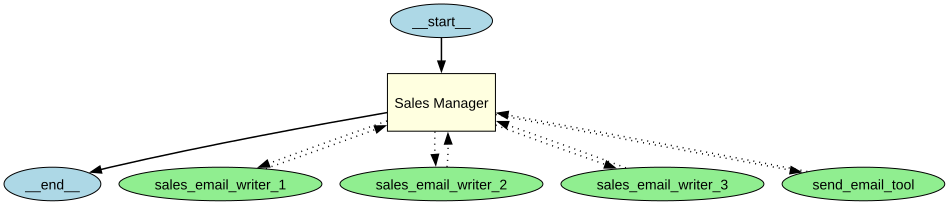

In [ ]:
# Visualize the agent graph
os.environ["PATH"] += os.pathsep + r"C:\Program Files\Graphviz\bin"

# draw the agent graph
draw_graph(sales_manager)